<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding How The Data Is Distributed**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform Exploratory Data Analysis (EDA). You will examine the structure of the data, visualize key variables, and analyze trends related to developer experience, tools, job satisfaction, and other important aspects.


## Objectives


In this lab you will perform the following:


- Understand the structure of the dataset.

- Perform summary statistics and data visualization.

- Identify trends in developer experience, tools, job satisfaction, and other key variables.


### Install the required libraries


In [1]:
# The original `!pip install` magic commands only run in Jupyter environments.
# They are kept below as comments. Use subprocess instead so the packages are
# installed with the same Python interpreter that is selected in VS Code.
# !pip install pandas
# !pip install matplotlib
# !pip install seaborn
import importlib.util
import subprocess
import sys

def install(package, import_name=None):
    """Quietly pip-install a package if it is not already available."""
    import_name = import_name or package
    try:
        spec = importlib.util.find_spec(import_name)
    except (ImportError, ModuleNotFoundError, ValueError):
        spec = None
    if spec is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])

install('pandas', 'pandas')
install('matplotlib', 'matplotlib')
install('seaborn', 'seaborn')

### Step 1: Import Libraries and Load Data


- Import the `pandas`, `matplotlib.pyplot`, and `seaborn` libraries.


- You will begin with loading the dataset. You can use the pyfetch method if working on JupyterLite. Otherwise, you can use pandas' read_csv() function directly on their local machines or cloud environments.


In [2]:
# Import necessary libraries
import os
import urllib.request
import urllib.error
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Stack Overflow survey dataset
# (cached locally so the notebook still runs when the network is down)
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
local_file = 'survey-data.csv'

def load_dataset(url, local_path, retries=3):
    if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
        try:
            return pd.read_csv(local_path)
        except Exception:
            pass
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            urllib.request.urlretrieve(url, local_path)
            return pd.read_csv(local_path)
        except (urllib.error.URLError, OSError) as e:
            last_err = e
            print(f"Download attempt {attempt}/{retries} failed: {e}")
    raise RuntimeError(
        "Could not download the dataset.\n"
        f"URL: {url}\nLast error: {last_err}\n"
        "Check your internet connection / VPN / proxy, or place a copy of the "
        f"CSV named '{local_path}' next to this notebook."
    )

df = load_dataset(data_url, local_file)

# Display the first few rows of the dataset
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Step 2: Examine the Structure of the Data


- Display the column names, data types, and summary information to understand the data structure.

- Objective: Gain insights into the dataset's shape and available variables.


In [3]:
## Write your code here
# Display column names, data types, and summary information
print("Shape:", df.shape)
print("\nColumn names:")
print(list(df.columns))
print("\nData types and non-null counts:")
df.info()
print("\nSummary statistics (numeric columns):")
print(df.describe())

Shape: (65437, 114)

Column names:
['ResponseId', 'MainBranch', 'Age', 'Employment', 'RemoteWork', 'Check', 'CodingActivities', 'EdLevel', 'LearnCode', 'LearnCodeOnline', 'TechDoc', 'YearsCode', 'YearsCodePro', 'DevType', 'OrgSize', 'PurchaseInfluence', 'BuyNewTool', 'BuildvsBuy', 'TechEndorse', 'Country', 'Currency', 'CompTotal', 'LanguageHaveWorkedWith', 'LanguageWantToWorkWith', 'LanguageAdmired', 'DatabaseHaveWorkedWith', 'DatabaseWantToWorkWith', 'DatabaseAdmired', 'PlatformHaveWorkedWith', 'PlatformWantToWorkWith', 'PlatformAdmired', 'WebframeHaveWorkedWith', 'WebframeWantToWorkWith', 'WebframeAdmired', 'EmbeddedHaveWorkedWith', 'EmbeddedWantToWorkWith', 'EmbeddedAdmired', 'MiscTechHaveWorkedWith', 'MiscTechWantToWorkWith', 'MiscTechAdmired', 'ToolsTechHaveWorkedWith', 'ToolsTechWantToWorkWith', 'ToolsTechAdmired', 'NEWCollabToolsHaveWorkedWith', 'NEWCollabToolsWantToWorkWith', 'NEWCollabToolsAdmired', 'OpSysPersonal use', 'OpSysProfessional use', 'OfficeStackAsyncHaveWorkedWith'

### Step 3: Handle Missing Data


- Identify missing values in the dataset.

- Impute or remove missing values as necessary to ensure data completeness.



In [4]:
## Write your code here
# Identify missing values in the dataset
missing = df.isna().sum().sort_values(ascending=False)
print("Columns with missing values (top 10):")
print(missing.head(10))
print("\nTotal missing values:", int(missing.sum()))

# Impute JobSat (numeric) with median and RemoteWork (categorical) with mode
if df['JobSat'].isna().any():
    df['JobSat'] = df['JobSat'].fillna(df['JobSat'].median())
if df['RemoteWork'].isna().any():
    df['RemoteWork'] = df['RemoteWork'].fillna(df['RemoteWork'].mode()[0])
print("\nAfter imputation - JobSat missing:", df['JobSat'].isna().sum(),
      "| RemoteWork missing:", df['RemoteWork'].isna().sum())

Columns with missing values (top 10):
AINextMuch less integrated       64289
AINextLess integrated            63082
AINextNo change                  52939
AINextMuch more integrated       51999
EmbeddedAdmired                  48704
EmbeddedWantToWorkWith           47837
EmbeddedHaveWorkedWith           43223
ConvertedCompYearly              42002
AIToolNot interested in Using    41023
AINextMore integrated            41009
dtype: int64

Total missing values: 2890957

After imputation - JobSat missing: 0 | RemoteWork missing: 0


### Step 4: Analyze Key Columns


- Examine key columns such as `Employment`, `JobSat` (Job Satisfaction), and `YearsCodePro` (Professional Coding Experience).

- **Instruction**: Calculate the value counts for each column to understand the distribution of responses.



In [5]:
## Write your code here
# Examine key columns: Employment, JobSat, YearsCodePro
print("=== Employment ===")
print(df['Employment'].value_counts())
print("\n=== JobSat ===")
print(df['JobSat'].value_counts().sort_index())
print("\n=== YearsCodePro ===")
print(df['YearsCodePro'].value_counts().head(15))

=== Employment ===
Employment
Employed, full-time                                                                                                                                   39041
Independent contractor, freelancer, or self-employed                                                                                                   4846
Student, full-time                                                                                                                                     4709
Employed, full-time;Independent contractor, freelancer, or self-employed                                                                               3557
Not employed, but looking for work                                                                                                                     2341
                                                                                                                                                      ...  
Not employed, but looking for work

### Step 5: Visualize Job Satisfaction (Focus on JobSat)


- Create a pie chart or KDE plot to visualize the distribution of `JobSat`.

- Provide an interpretation of the plot, highlighting key trends in job satisfaction.


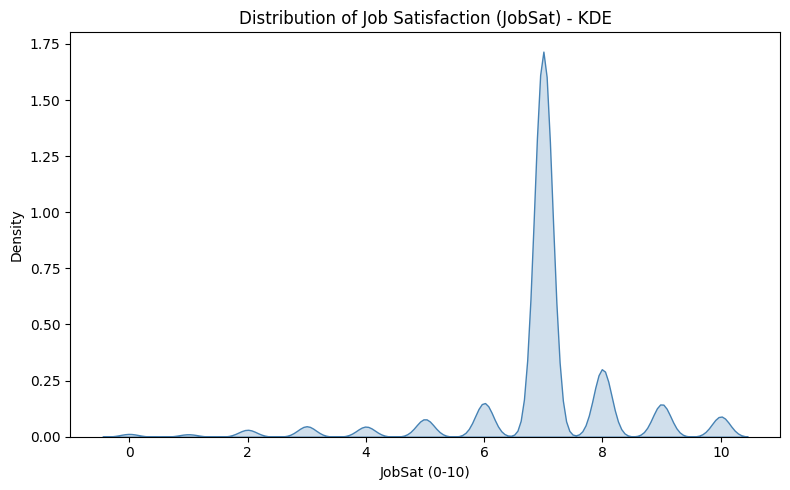

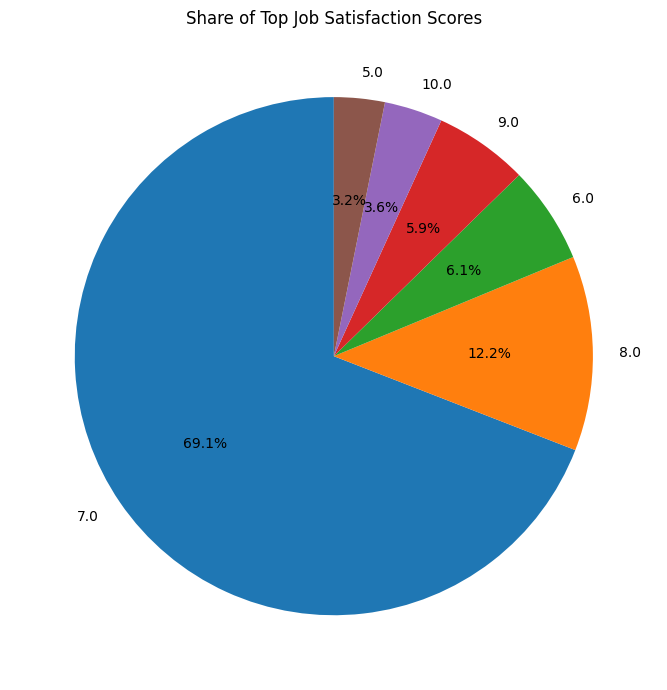

In [6]:
## Write your code here
# KDE plot of the JobSat distribution
plt.figure(figsize=(8, 5))
sns.kdeplot(df['JobSat'].dropna(), fill=True, color='steelblue')
plt.title('Distribution of Job Satisfaction (JobSat) - KDE')
plt.xlabel('JobSat (0-10)')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

# Pie chart of the most common JobSat scores
top_sat = df['JobSat'].value_counts().head(6)
plt.figure(figsize=(7, 7))
top_sat.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Share of Top Job Satisfaction Scores')
plt.ylabel('')
plt.tight_layout()
plt.show()

### Step 6: Programming Languages Analysis


- Compare the frequency of programming languages in `LanguageHaveWorkedWith` and `LanguageWantToWorkWith`.
  
- Visualize the overlap or differences using a Venn diagram or a grouped bar chart.


Top languages worked with:
LanguageHaveWorkedWith
JavaScript                 37492
HTML/CSS                   31816
Python                     30719
SQL                        30682
TypeScript                 23150
Bash/Shell (all shells)    20412
Java                       18239
C#                         16318
C++                        13827
C                          12184
Name: count, dtype: int64

Top languages wanted to work with:
LanguageWantToWorkWith
Python                     25047
JavaScript                 23774
SQL                        22400
HTML/CSS                   20721
TypeScript                 20239
Rust                       17232
Go                         13837
Bash/Shell (all shells)    13744
C#                         12921
C++                        10873
Name: count, dtype: int64


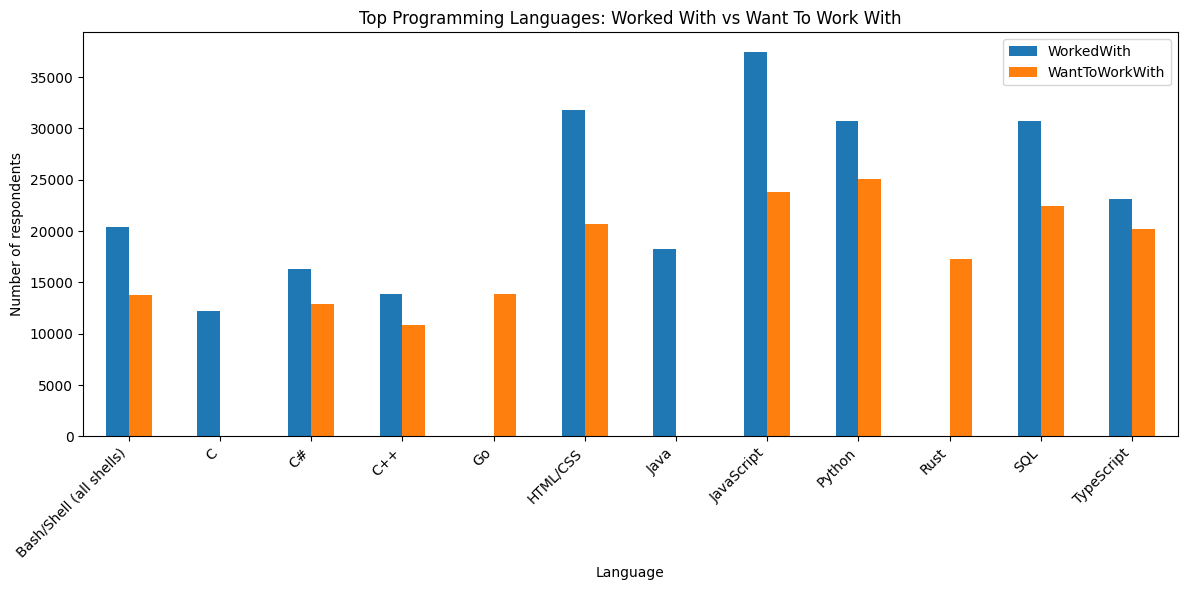

In [7]:
## Write your code here
# Compare frequency of languages in LanguageHaveWorkedWith vs LanguageWantToWorkWith
worked = df['LanguageHaveWorkedWith'].dropna().str.split(';').explode().value_counts()
wanted = df['LanguageWantToWorkWith'].dropna().str.split(';').explode().value_counts()

top_n = 10
top_worked = worked.head(top_n)
top_wanted = wanted.head(top_n)

print("Top languages worked with:")
print(top_worked)
print("\nTop languages wanted to work with:")
print(top_wanted)

# Grouped bar chart of the overlap
lang_compare = pd.DataFrame({
    'WorkedWith': top_worked,
    'WantToWorkWith': top_wanted,
}).fillna(0)
lang_compare.plot(kind='bar', figsize=(12, 6))
plt.title('Top Programming Languages: Worked With vs Want To Work With')
plt.xlabel('Language')
plt.ylabel('Number of respondents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Step 7: Analyze Remote Work Trends


- Visualize the distribution of RemoteWork by region using a grouped bar chart or heatmap.


RemoteWork                                          Hybrid (some remote, some in-person)  \
Country                                                                                    
France                                                                              1344   
Germany                                                                             3098   
India                                                                               2290   
Ukraine                                                                              828   
United Kingdom of Great Britain and Northern Ir...                                  1765   
United States of America                                                            4857   

RemoteWork                                          In-person  Remote  
Country                                                                
France                                                    357     409  
Germany                                        

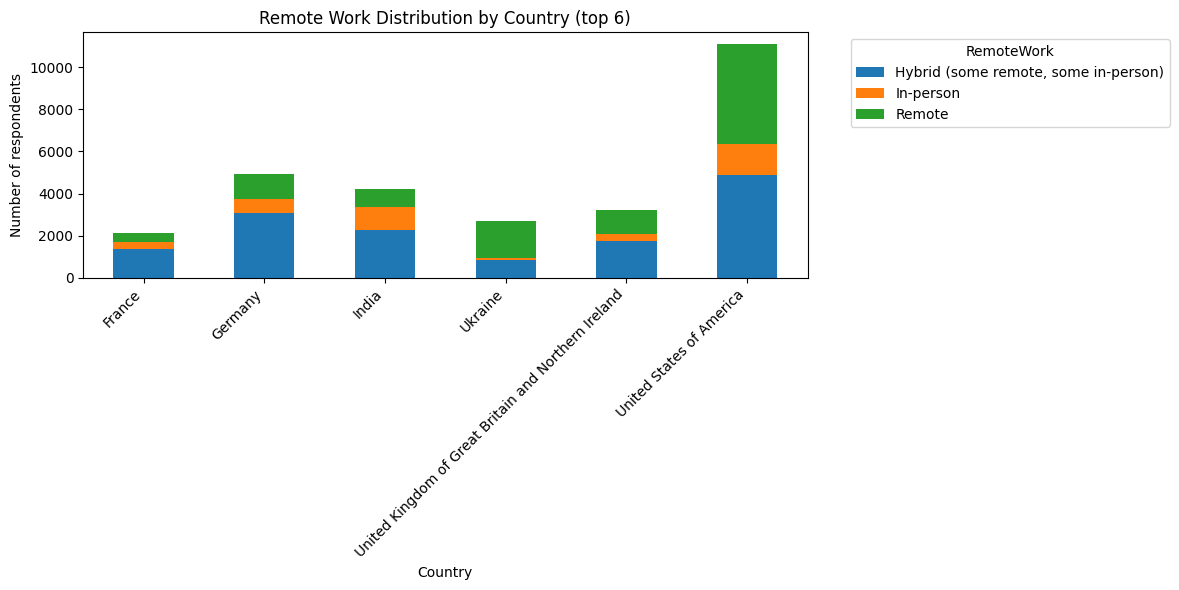

In [8]:
## Write your code here
# Visualize distribution of RemoteWork by region (top countries)
top_countries = df['Country'].value_counts().head(6).index.tolist()
subset = df[df['Country'].isin(top_countries)]

ct = pd.crosstab(subset['Country'], subset['RemoteWork'])
print(ct)

ct.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Remote Work Distribution by Country (top 6)')
plt.xlabel('Country')
plt.ylabel('Number of respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='RemoteWork', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Step 8: Correlation between Job Satisfaction and Experience


- Analyze the correlation between overall job satisfaction (`JobSat`) and `YearsCodePro`.
  
- Calculate the Pearson or Spearman correlation coefficient.


In [9]:
## Write your code here
# Convert YearsCodePro to numeric for correlation
def to_years(val):
    if pd.isna(val):
        return None
    if isinstance(val, str):
        if val == 'Less than 1 year':
            return 0.5
        if val == 'More than 50 years':
            return 50
        try:
            return float(val)
        except ValueError:
            return None
    return float(val)

df['YearsCodePro_num'] = df['YearsCodePro'].apply(to_years)

# Pearson correlation
pearson = df[['YearsCodePro_num', 'JobSat']].corr(method='pearson').iloc[0, 1]
spearman = df[['YearsCodePro_num', 'JobSat']].corr(method='spearman').iloc[0, 1]
print("Pearson correlation:", round(pearson, 4))
print("Spearman correlation:", round(spearman, 4))

Pearson correlation: 0.072
Spearman correlation: 0.09


### Step 9: Cross-tabulation Analysis (Employment vs. Education Level)


- Analyze the relationship between employment status (`Employment`) and education level (`EdLevel`).

- **Instruction**: Create a cross-tabulation using `pd.crosstab()` and visualize it with a stacked bar plot if possible.


EdLevel                                             Associate degree (A.A., A.S., etc.)  \
Employment                                                                                
Employed, full-time                                                                1059   
Employed, full-time;Employed, part-time                                               9   
Employed, full-time;Independent contractor, fre...                                  104   
Employed, full-time;Independent contractor, fre...                                   11   
Employed, full-time;Independent contractor, fre...                                    0   
...                                                                                 ...   
Student, full-time;Student, part-time;Employed,...                                    0   
Student, full-time;Student, part-time;Retired                                         0   
Student, part-time                                                                   12   

C:\Users\Jerome\AppData\Local\Temp\ipykernel_19772\566320098.py:13: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


<Figure size 1200x600 with 0 Axes>

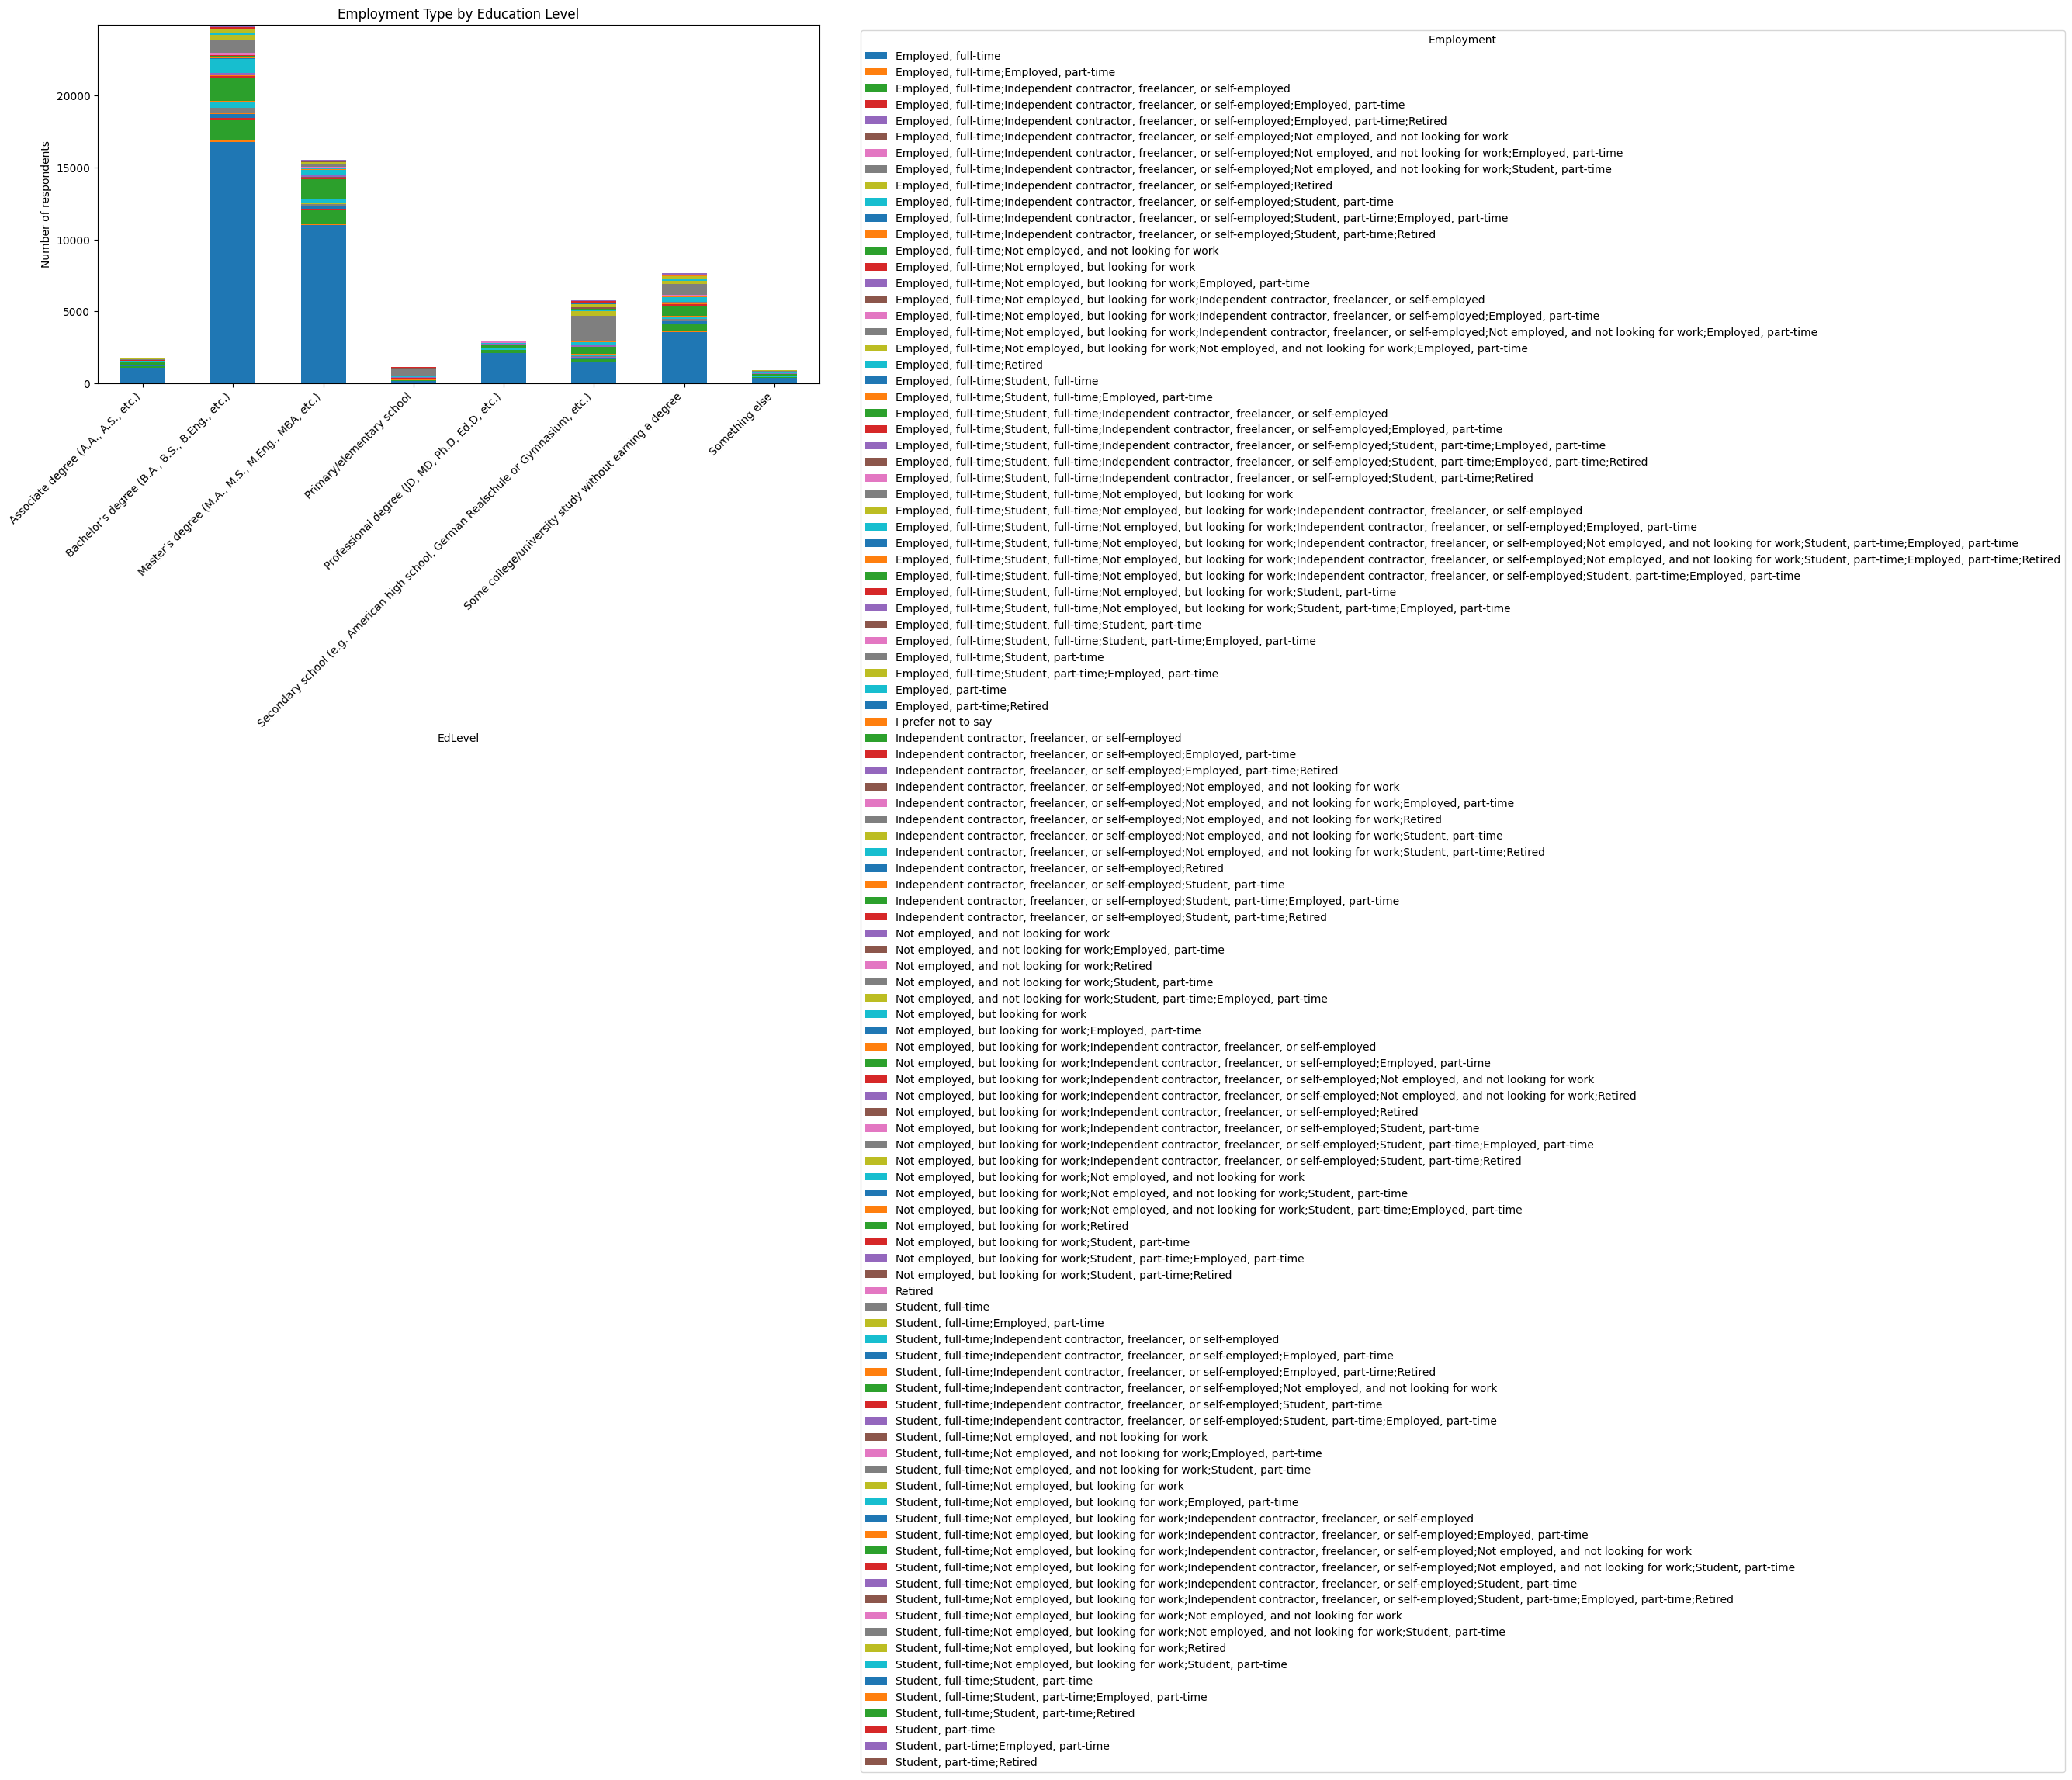

In [10]:
## Write your code here
# Cross-tabulation of Employment vs EdLevel
ct = pd.crosstab(df['Employment'], df['EdLevel'])
print(ct)

plt.figure(figsize=(12, 6))
ct.T.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Employment Type by Education Level')
plt.xlabel('EdLevel')
plt.ylabel('Number of respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Employment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Step 10: Export Cleaned Data


- Save the cleaned dataset to a new CSV file for further use or sharing.


In [11]:
## Write your code here
# Save the cleaned dataset to a new CSV file
output_file = 'survey_data_distributed.csv'
df.to_csv(output_file, index=False)
print("Saved cleaned dataset to", output_file)
print("Shape:", df.shape)

Saved cleaned dataset to survey_data_distributed.csv
Shape: (65437, 115)


### Summary:


In this lab, you practiced key skills in exploratory data analysis, including:


- Examining the structure and content of the Stack Overflow survey dataset to understand its variables and data types.

- Identifying and addressing missing data to ensure the dataset's quality and completeness.

- Summarizing and visualizing key variables such as job satisfaction, programming languages, and remote work trends.

- Analyzing relationships in the data using techniques like:
    - Comparing programming languages respondents have worked with versus those they want to work with.
      
    - Exploring remote work preferences by region.

- Investigating correlations between professional coding experience and job satisfaction.

- Performing cross-tabulations to analyze relationships between employment status and education levels.


## Authors:
Ayushi Jain


### Other Contributors:
Rav Ahuja
Lakshmi Holla
Malika


Copyright © IBM Corporation. All rights reserved.
